In [2]:
import os
os.environ['OMP_NUM_THREADS']      = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS']      = '1'

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math, json, datetime
from scipy import signal

In [3]:
TEST    = json.loads(open('../info.json', 'r').read()).get('test', 1)
RESULTS = f'../Dataset/test{TEST}/results'
SOURCE  = f'{RESULTS}/dataset.csv'
print('SOURCE:', SOURCE)

SOURCE: ../Dataset/test1/results/dataset.csv


# IMPORTANDO DADOS
- Saída do `Dataset/Format.ipynb`: o MRU nos eixos do Kernel e na escala do `SCALE_MODE`, sem defasagem, na grade de $\Delta t$ e sem o buraco da gravação

In [4]:
df      = pd.read_csv(SOURCE)
SENSORS = ['ax', 'ay', 'az', 'wx', 'wy', 'wz']
dt      = round(float(df.time.diff().median()), 4)
NYQUIST = 0.5 / dt

print(len(df), 'amostras de', dt, 's')
df.head()

1800 amostras de 0.1 s


,time,static,tmp,ax,ay,az,wx,wy,wz,pitch,roll,yaw,ref_pitch,ref_roll,ref_yaw,ref_wx,ref_wy,ref_wz
0,0.0,False,53.0,0.194623,-0.614769,10.733555,-47.92960,-6.92455,1.16726,18.043,1.525,2.936,0.304871,-71.390541,2.771970,-48.363254,-0.461426,0.424375
1,0.1,False,52.9,0.294719,-0.532550,11.618576,-58.13591,-8.13221,1.05996,12.732,0.742,2.725,0.337243,-76.661753,2.723841,-56.744132,1.081554,0.104249
2,0.2,False,53.1,0.256924,-2.312996,12.899422,-67.53252,-8.42212,1.95110,6.586,-0.119,2.578,0.366750,-82.677810,2.667691,-63.259749,-0.383746,0.248578
3,0.3,False,53.3,0.425020,-0.455019,12.406766,-67.39252,-9.92099,1.05936,-0.016,-1.010,2.655,0.387721,-89.209529,2.743322,-66.654402,0.041597,0.372268
4,0.4,False,52.9,0.271203,-0.208931,12.362390,-66.62502,-9.44709,1.97845,-6.779,-1.984,2.656,0.442381,-95.913135,2.624720,-67.172037,1.487548,0.737216


# VISUALIZAÇÃO DOS DADOS

In [5]:
MOTION = (~df.static)
LIMITS = (40, 60)
df

,time,static,tmp,ax,ay,az,wx,wy,wz,pitch,roll,yaw,ref_pitch,ref_roll,ref_yaw,ref_wx,ref_wy,ref_wz
0,0.0,False,53.0,0.194623,-0.614769,10.733555,-47.92960,-6.92455,1.16726,18.043,1.525,2.936,0.304871,-71.390541,2.771970,-48.363254,-0.461426,0.424375
1,0.1,False,52.9,0.294719,-0.532550,11.618576,-58.13591,-8.13221,1.05996,12.732,0.742,2.725,0.337243,-76.661753,2.723841,-56.744132,1.081554,0.104249
2,0.2,False,53.1,0.256924,-2.312996,12.899422,-67.53252,-8.42212,1.95110,6.586,-0.119,2.578,0.366750,-82.677810,2.667691,-63.259749,-0.383746,0.248578
3,0.3,False,53.3,0.425020,-0.455019,12.406766,-67.39252,-9.92099,1.05936,-0.016,-1.010,2.655,0.387721,-89.209529,2.743322,-66.654402,0.041597,0.372268
4,0.4,False,52.9,0.271203,-0.208931,12.362390,-66.62502,-9.44709,1.97845,-6.779,-1.984,2.656,0.442381,-95.913135,2.624720,-67.172037,1.487548,0.737216
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1795,279.4,True,55.5,0.269369,-0.416959,9.760873,-0.09321,-0.21920,-0.25104,-2.510,-1.368,5.289,1.644962,-92.131613,6.371291,0.026304,0.007389,0.002918
1796,279.5,True,55.6,0.235938,-0.402014,9.717615,-0.09929,-0.00493,0.03678,-2.509,-1.368,5.289,1.645535,-92.131613,6.371291,-0.006860,0.005699,-0.000058
1797,279.6,True,55.4,0.257170,-0.404622,9.768983,-0.18597,0.50338,-0.40111,-2.506,-1.367,5.291,1.644962,-92.131613,6.371291,0.001138,-0.030184,-0.002684
1798,279.7,True,55.6,0.266545,-0.485586,9.796167,0.06592,0.14588,0.14609,-2.506,-1.367,5.289,1.645535,-92.131613,6.377020,-0.002625,-0.056662,0.004405


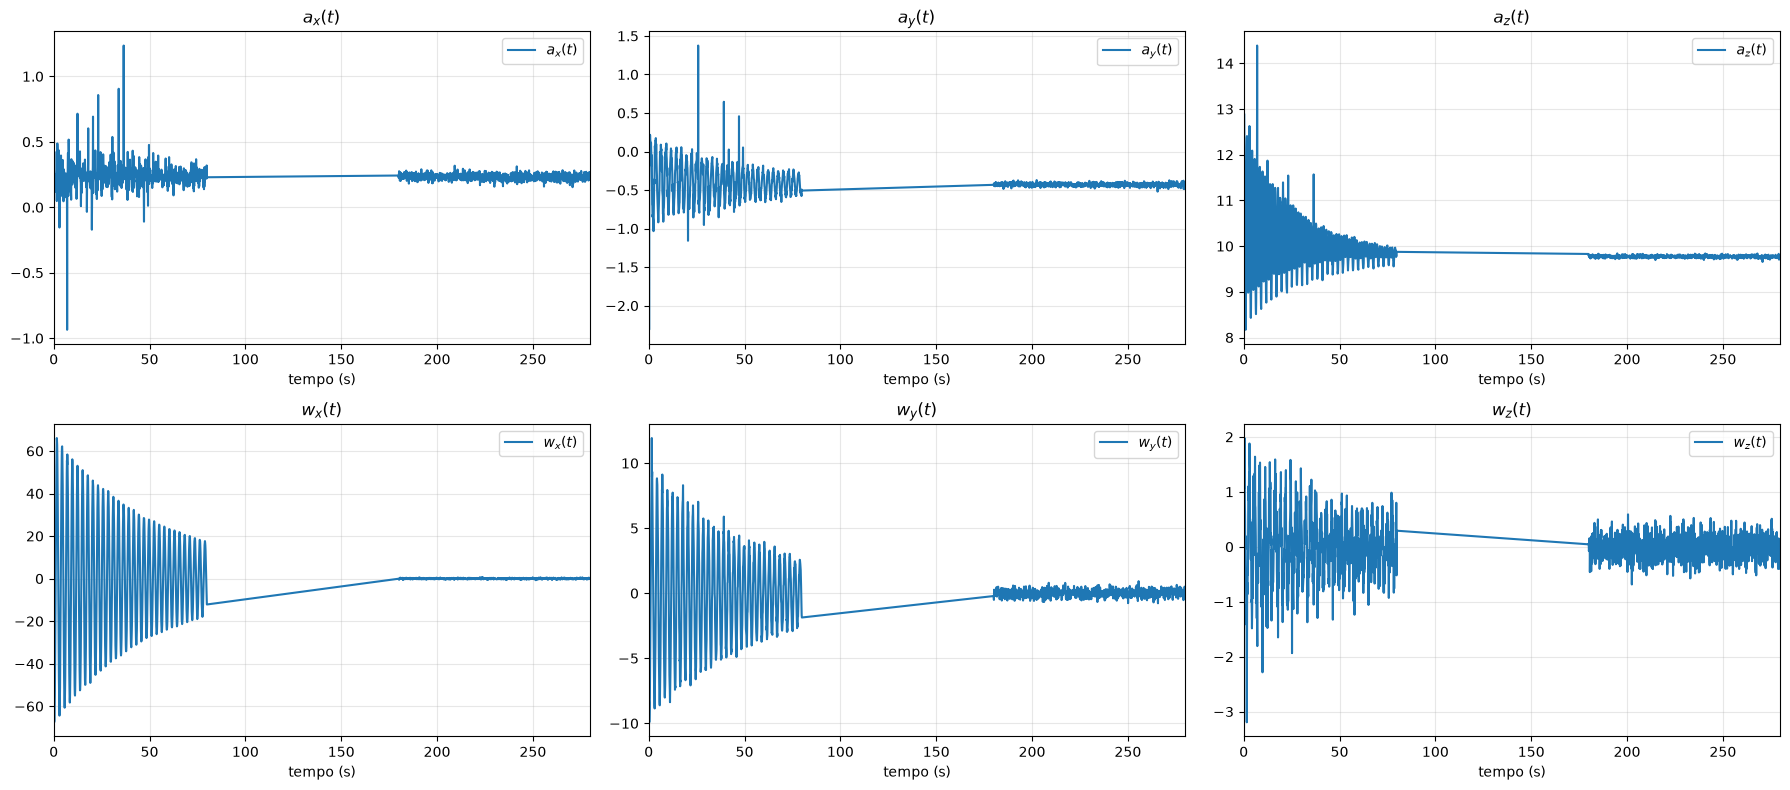

In [6]:
def compareAxis(time, data, limits=(0, 1), yLim=None):
    t_min, t_max = time.min(), time.max()
    delta = (t_max - t_min)

    start_time = t_min + (delta * limits[0])
    end_time   = t_min + (delta * limits[1])

    count   = len(data.keys())
    numCols = 3 if count >= 3 else count
    numRows = math.ceil(count / numCols)
    plt.figure(figsize=(6*numCols, 4*numRows))

    for i, (key, values) in enumerate(data.items()):
        mask = (time >= start_time) & (time <= end_time)

        plt.subplot(numRows, numCols, i+1)
        plt.plot(time[mask], values[mask], label=key)

        plt.xlim(start_time, end_time)
        if yLim: plt.ylim(yLim)
        plt.title(key); plt.xlabel('tempo (s)')
        plt.grid(alpha=0.3); plt.legend()

    plt.tight_layout()
    plt.show()

def plotAll(df, limits=(0, 1)):
    compareAxis(df.time, {
        '$a_x(t)$': df.ax, '$a_y(t)$': df.ay, '$a_z(t)$': df.az,
        '$w_x(t)$': df.wx, '$w_y(t)$': df.wy, '$w_z(t)$': df.wz
    }, limits)


plotAll(df, limits=(0, 1))

# FILTROS
### PASSA BAIXA
- Quatro polos reais em $2\pi F_c$ por Tustin, o mesmo `LowPassFilter` do firmware: o −3 dB cai em $\approx 0{,}435\,F_c$, não em $F_c$

In [7]:
# QUATRO POLOS REAIS EM Fc POR TUSTIN, ESPELHO DO FIRMWARE
class LowPassFilter:
    def __init__(self, Fc, dt):
        self.dt = dt
        self.Fc = Fc

        Wc = (2 * np.pi * Fc)
        num_c = [Wc**4]
        den_c = [1, 4*Wc, 6*(Wc**2), 4*(Wc**3), Wc**4]

        C = signal.cont2discrete((num_c, den_c), dt, method='bilinear')
        self.num, self.den = self.getFraction(C)
        self.reset()

    def getFraction(self, C):
        num = np.squeeze(C[0])
        den = np.squeeze(C[1])
        num = num / den[0]
        den = den / den[0]
        return num.tolist(), den.tolist()

    def compute(self):
        return np.dot(self.Xn, self.num) - np.dot(self.Yn[1:], self.den[1:])

    def update(self, inputValue):
        self.Xn[1:] = self.Xn[:-1].copy()
        self.Yn[1:] = self.Yn[:-1].copy()
        self.Xn[0]  = inputValue
        self.Yn[0]  = self.compute()
        return self.Yn[0] if self.Fc > 0 else inputValue

    # ESTADOS NO VALOR INICIAL: REGIME PERMANENTE, SEM O TRANSITÓRIO DE PARTIDA DO ZERO
    def reset(self, value=0.0):
        self.Xn = np.full(len(self.num), value)
        self.Yn = np.full(len(self.den), value)

    # O MESMO update() EM C, PARTINDO EM REGIME NO PRIMEIRO VALOR: A 200 Hz O LAÇO EM PYTHON NÃO CABE NA BUSCA
    def apply(self, yData):
        yData = np.asarray(yData, dtype=float)
        return signal.lfilter(self.num, self.den, yData, zi=signal.lfilter_zi(self.num, self.den) * (yData[0] if len(yData) else 0.0))[0]

    # DESENHA NO EIXO QUE O CHAMADOR ABRIU
    def test(self, df, var, limits):
        window   = (df.time >= limits[0]) & (df.time <= limits[1])
        filtered = self.apply(df[var])

        plt.scatter(df.time[window], df[var][window], label='bruto', s=5, color='orange')
        plt.plot(df.time[window], filtered[window], label=f'Fc={self.Fc:.3g} Hz', linewidth=2)
        plt.title('Filtro Passa Baixa (Valores)'); plt.xlabel('tempo (s)'); plt.ylabel(var); plt.grid(alpha=0.3); plt.legend(loc='upper right')
        return filtered

### FILTRO DE BUTTERWORTH
- Segunda ordem por Tustin com pré-distorção, o mesmo `ButterworthFilter` do firmware: `f_c` é fração de Nyquist, então `f_c = 0.3` corta em 1,5 Hz

In [8]:
# BUTTERWORTH DE SEGUNDA ORDEM COM PRÉ-DISTORÇÃO, ESPELHO DO FIRMWARE
class ButterworthFilter:
    def __init__(self, f_c):
        self.f_c = f_c / 2.0
        self.b, self.a = self.getCoefs()
        self.reset()

    def getCoefs(self):
        wc = math.tan(math.pi * self.f_c)
        c2 = wc*wc
        norm = 1 + math.sqrt(2)*wc + c2

        b0 = c2/norm
        b1 = 2*c2/norm
        b2 = c2/norm

        a1 = 2*(c2 - 1)/norm
        a2 = (1 - math.sqrt(2)*wc + c2)/norm
        return [b0, b1, b2], [1.0, -a1, -a2]

    def update(self, Xn):
        Yn = self.b[0]*Xn + self.b[1]*self.Xn1 + self.b[2]*self.Xn2 + self.a[1]*self.Yn1 + self.a[2]*self.Yn2
        self.Xn2, self.Xn1 = self.Xn1, Xn
        self.Yn2, self.Yn1 = self.Yn1, Yn
        return Yn

    def reset(self, value=0.0):
        self.Xn1 = self.Xn2 = value
        self.Yn1 = self.Yn2 = value

    # O MESMO update() EM C, PARTINDO EM REGIME NO PRIMEIRO VALOR: y + a1 y1 + a2 y2 = b x
    def apply(self, data):
        data = np.asarray(data, dtype=float)
        den  = [1.0, -self.a[1], -self.a[2]]
        return signal.lfilter(self.b, den, data, zi=signal.lfilter_zi(self.b, den) * (data[0] if len(data) else 0.0))[0]

    # DESENHA NO EIXO QUE O CHAMADOR ABRIU
    def test(self, df, var, limits):
        window   = (df.time >= limits[0]) & (df.time <= limits[1])
        filtered = self.apply(df[var])

        plt.scatter(df.time[window], df[var][window], label='bruto', s=5, color='orange')
        plt.plot(df.time[window], filtered[window], label=f'f_c={2*self.f_c:.3g}', linewidth=2)
        plt.title('Butterworth (Valores)'); plt.xlabel('tempo (s)'); plt.ylabel(var); plt.grid(alpha=0.3); plt.legend(loc='upper right')
        return filtered

### FILTRO DE MÉDIA EXPONENCIAL

In [9]:
# PRIMEIRA ORDEM y = αx + (1 − α)y₋₁
class ExponentialFilter:
    def __init__(self, alpha):
        self.alpha = alpha

    def apply(self, data):
        return pd.Series(np.asarray(data, dtype=float)).ewm(alpha=self.alpha, adjust=False).mean().to_numpy()

    # DESENHA NO EIXO QUE O CHAMADOR ABRIU
    def test(self, df, var, limits):
        window   = (df.time >= limits[0]) & (df.time <= limits[1])
        filtered = self.apply(df[var])

        plt.scatter(df.time[window], df[var][window], label='bruto', s=5, color='orange')
        plt.plot(df.time[window], filtered[window], label=f'α={self.alpha:.3g}', linewidth=2)
        plt.title('Média Exponencial (Valores)'); plt.xlabel('tempo (s)'); plt.ylabel(var); plt.grid(alpha=0.3); plt.legend(loc='upper right')
        return filtered

# OTIMIZAÇÃO DOS PARÂMETROS
- A `objective` devolve $\varepsilon$, o erro RMS entre o filtrado e o movimento verdadeiro **no mesmo instante**, dividido pelo erro do sinal cru: o atraso entra no erro, porque é o que o firmware entrega
- No trecho em movimento o espectro de Welch é sinal mais ruído, $P = S + N$. O pêndulo ocupa poucas raias, então a mediana de $P$ é o piso $N$ e $S = \max(P - N,\ 0)$
- Todo filtro aqui é linear e fica descrito pela resposta $H(f)$ ao impulso, então

$$\varepsilon^2 = \frac{\sum_f |1 - H(f)|^2\,S(f) + |H(f)|^2\,N(f)}{\sum_f N(f)}$$

- A primeira parcela é o sinal que o filtro atenua ou atrasa, a segunda o ruído que ele deixa passar. Sem filtro ($H = 1$) sobra o ruído inteiro e $\varepsilon = 1$: abaixo de 1 o filtro ajuda, acima dele piora o sinal
- Todo filtro é buscado pelo corte em $\log_{10}$ Hz: o corte varia por décadas, a CMA-ES usa um passo só para a caixa inteira, e em Hz a busca, o trecho do Welch e o impulso valem para qualquer taxa de aquisição

In [10]:
from Nature.index import NatureSelector

In [11]:
LOWEST = math.log10(0.05)    # Hz: PERÍODO DE 20 s, O LIMITE DE ONDA QUE NENHUM FILTRO PODE CORTAR

FILTERS = {
    'low_pass': {
        'filter': lambda log_fc: LowPassFilter(10**log_fc, dt),
        'variables': {'log_fc': {'bounds': (LOWEST, math.log10(1/(math.pi*dt)))}}
    },
    'butterworth': {
        'filter': lambda log_fc: ButterworthFilter(10**log_fc / NYQUIST),
        'variables': {'log_fc': {'bounds': (LOWEST, math.log10(0.99*NYQUIST))}}
    },
    'exponential': {
        'filter': lambda log_fc: ExponentialFilter(1 - math.exp(-2*math.pi*10**log_fc*dt)),
        'variables': {'log_fc': {'bounds': (LOWEST, math.log10(10*NYQUIST))}}    # 10 NYQUIST JÁ É α ≈ 1, NÃO FILTRAR
    }
}

SEARCH = {'population': 30, 'generations': 150, 'seed': 42}    # BATE A VARREDURA DENSA NAS 18 BUSCAS
RUNS   = 5                                                     # CORRIDAS INDEPENDENTES, SEMENTES 42 A 46: FICA A MELHOR

In [12]:
SEGMENT = 12.8    # s DO TRECHO DO WELCH: RAIAS DE 0,08 Hz, FINAS O BASTANTE PARA O PERÍODO DE ONDA


# ε: ERRO DO FILTRADO CONTRA O MOVIMENTO VERDADEIRO NO MESMO INSTANTE, DIVIDIDO PELO ERRO DO SINAL CRU
def objective(filter, params, data=None):
    data = df.loc[MOTION, TARGET] if data is None else data
    size = int(round(SEGMENT / dt))
    P = signal.welch(np.asarray(data, dtype=float), nperseg=size)[1]
    N = np.median(P)                                                                     # O MOVIMENTO OCUPA POUCAS RAIAS: A MEDIANA É O PISO DE RUÍDO
    S = np.clip(P - N, 0, None)
    h = FILTERS[filter]['filter'](**params).apply(signal.unit_impulse(8*size, 'mid'))    # 8 JANELAS DE COMPRIMENTO: O FILTRO MAIS LENTO DECAI
    H = np.fft.rfft(np.roll(h, -4*size))[::8]                                            # IMPULSO DE VOLTA EM n = 0, LIDO NAS RAIAS DO WELCH
    return np.sqrt(np.sum(np.abs(1 - H)**2*S + np.abs(H)**2*N) / (N*len(P)))


rankings = {}

### ACELERAÇÃO EM X ($a_x$)

genetic: 100%|██████████| 22110/22110 [00:12<00:00, 1765.24ev/s, best=0.538901, pop=120]


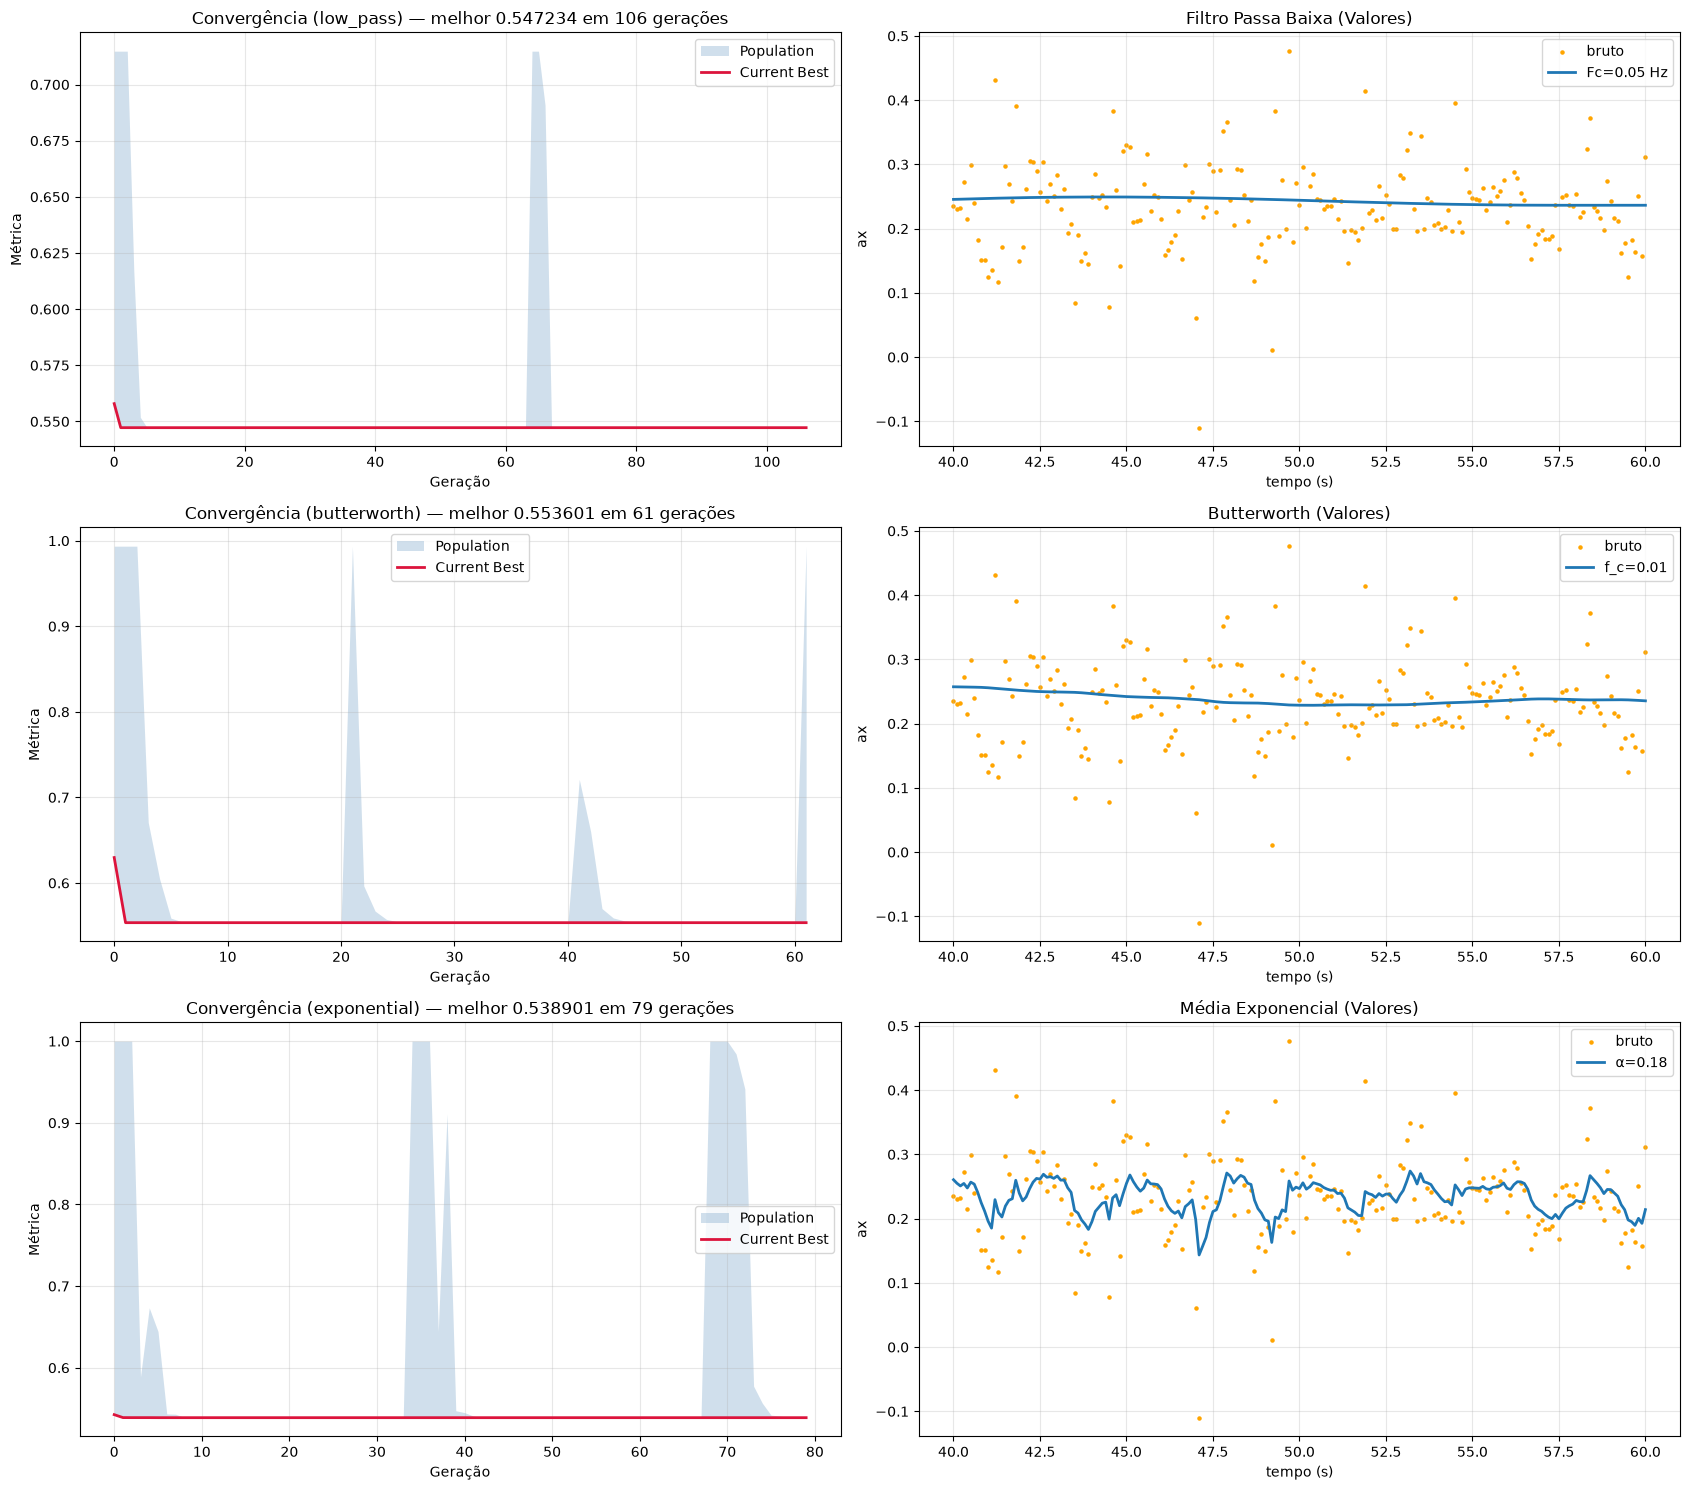

,error,params
exponential,0.538901,{'log_fc': -0.5017554408937143}
low_pass,0.547234,{'log_fc': -1.3010299922074877}
butterworth,0.553601,{'log_fc': -1.3010299956639813}


In [13]:
TARGET = 'ax'
models = {
    filter: NatureSelector('genetic', {
            'objective': lambda params, filter=filter: objective(filter, params),
            'maximize': False, 'verbose': True, 'variables': option['variables'], **SEARCH
        }, n_gaussian=RUNS
    ) for filter, option in FILTERS.items()
}

for model in models.values():
    model.update()

plt.figure(figsize=(17, 5*len(models)))
for i, (filter, model) in enumerate(models.items()):
    portrait      = model.portrait()
    portrait.name = filter
    plt.subplot(len(models), 2, 2*i + 1); portrait.metrics(plt.gca())
    plt.subplot(len(models), 2, 2*i + 2); FILTERS[filter]['filter'](**model.best).test(df[MOTION], TARGET, LIMITS)

plt.tight_layout()
plt.show()

rankings[TARGET] = {filter: {'error': model.score, 'params': model.best} for filter, model in models.items()}
pd.DataFrame(rankings[TARGET]).T.sort_values('error')

### ACELERAÇÃO EM Y ($a_y$)

genetic: 100%|██████████| 22020/22020 [00:12<00:00, 1763.95ev/s, best=0.714667, pop=120]


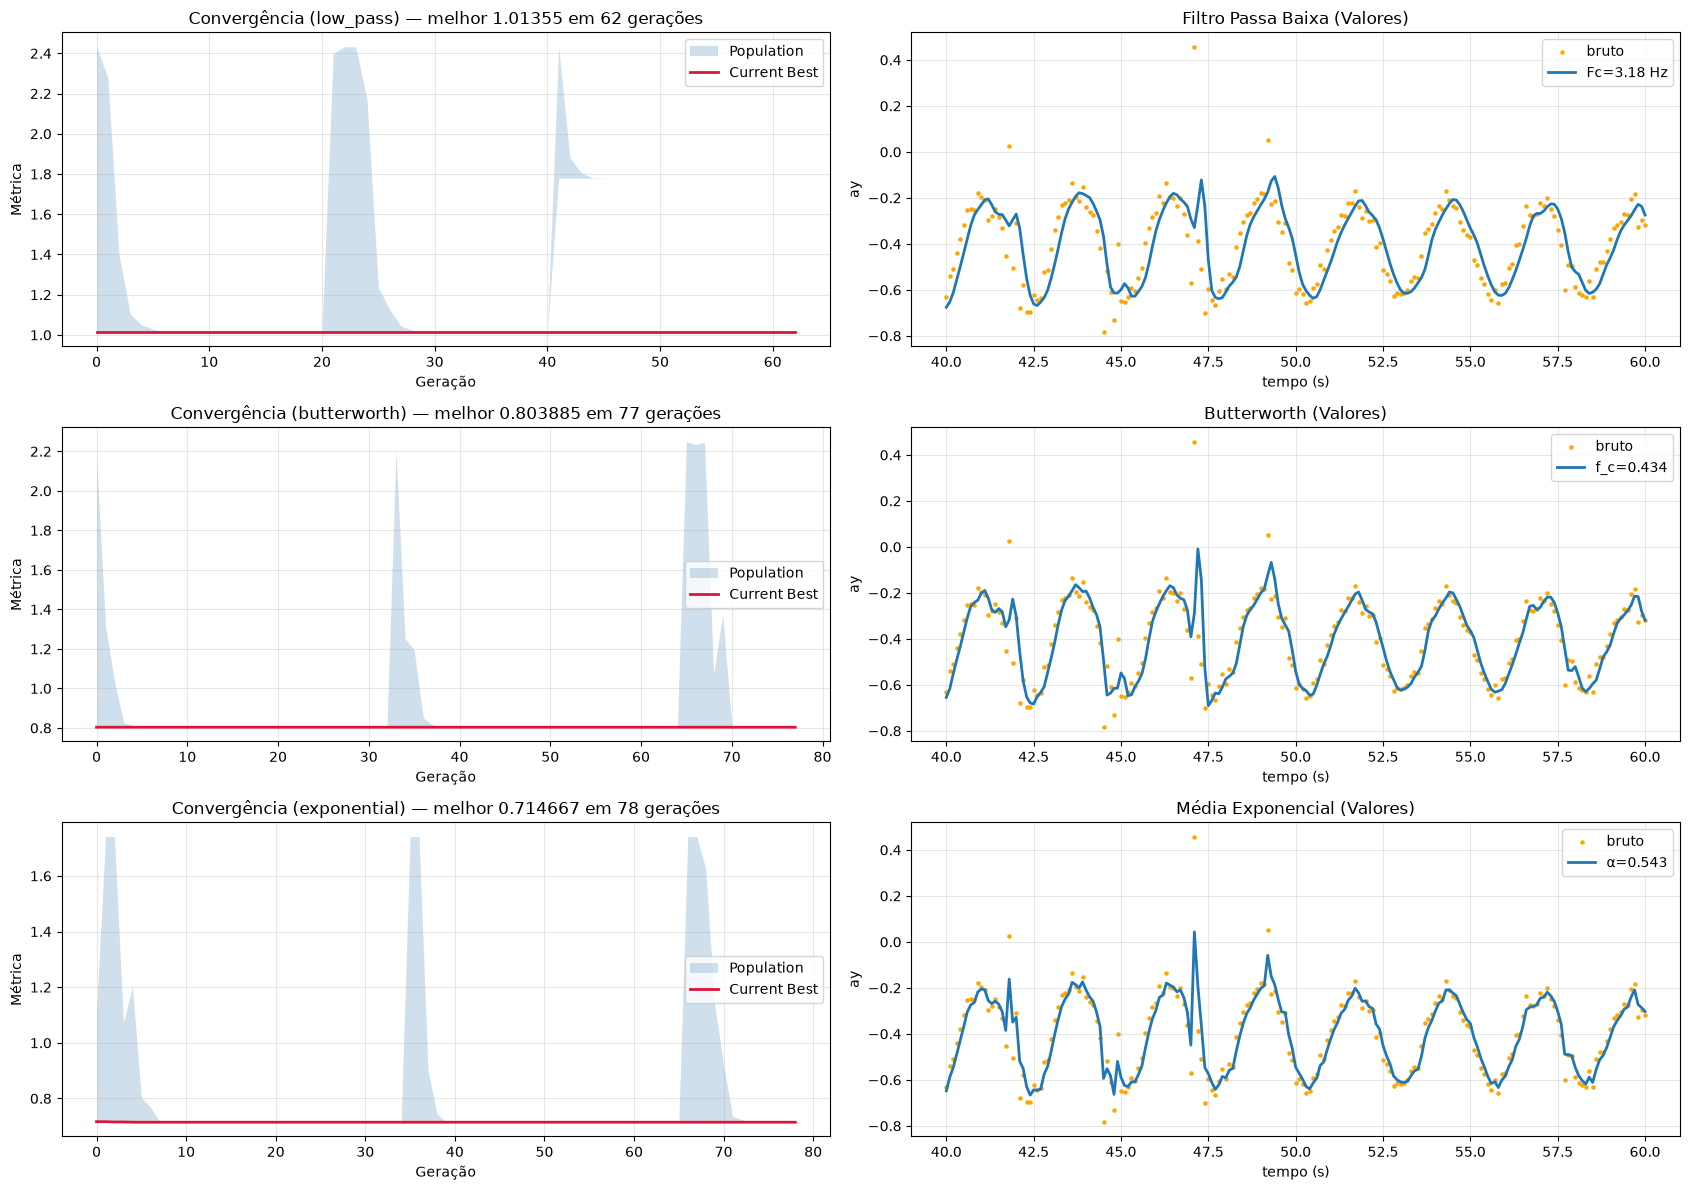

,error,params
exponential,0.714667,{'log_fc': 0.0956083868728886}
butterworth,0.803885,{'log_fc': 0.336805394975996}
low_pass,1.013546,{'log_fc': 0.5028501273058662}


In [14]:
TARGET = 'ay'
models = {
    filter: NatureSelector('genetic', {
            'objective': lambda params, filter=filter: objective(filter, params),
            'maximize': False, 'verbose': True, 'variables': option['variables'], **SEARCH
        }, n_gaussian=RUNS
    ) for filter, option in FILTERS.items()
}

for model in models.values():
    model.update()

plt.figure(figsize=(17, 4*len(models)))
for i, (filter, model) in enumerate(models.items()):
    portrait      = model.portrait()
    portrait.name = filter 
    plt.subplot(len(models), 2, 2*i + 1); portrait.metrics(plt.gca())
    plt.subplot(len(models), 2, 2*i + 2); FILTERS[filter]['filter'](**model.best).test(df[MOTION], TARGET, LIMITS)

plt.tight_layout()
plt.show()

rankings[TARGET] = {filter: {'error': model.score, 'params': model.best} for filter, model in models.items()}
pd.DataFrame(rankings[TARGET]).T.sort_values('error')

### ACELERAÇÃO EM Z ($a_z$)

genetic: 100%|██████████| 22140/22140 [00:12<00:00, 1762.46ev/s, best=0.925701, pop=120]


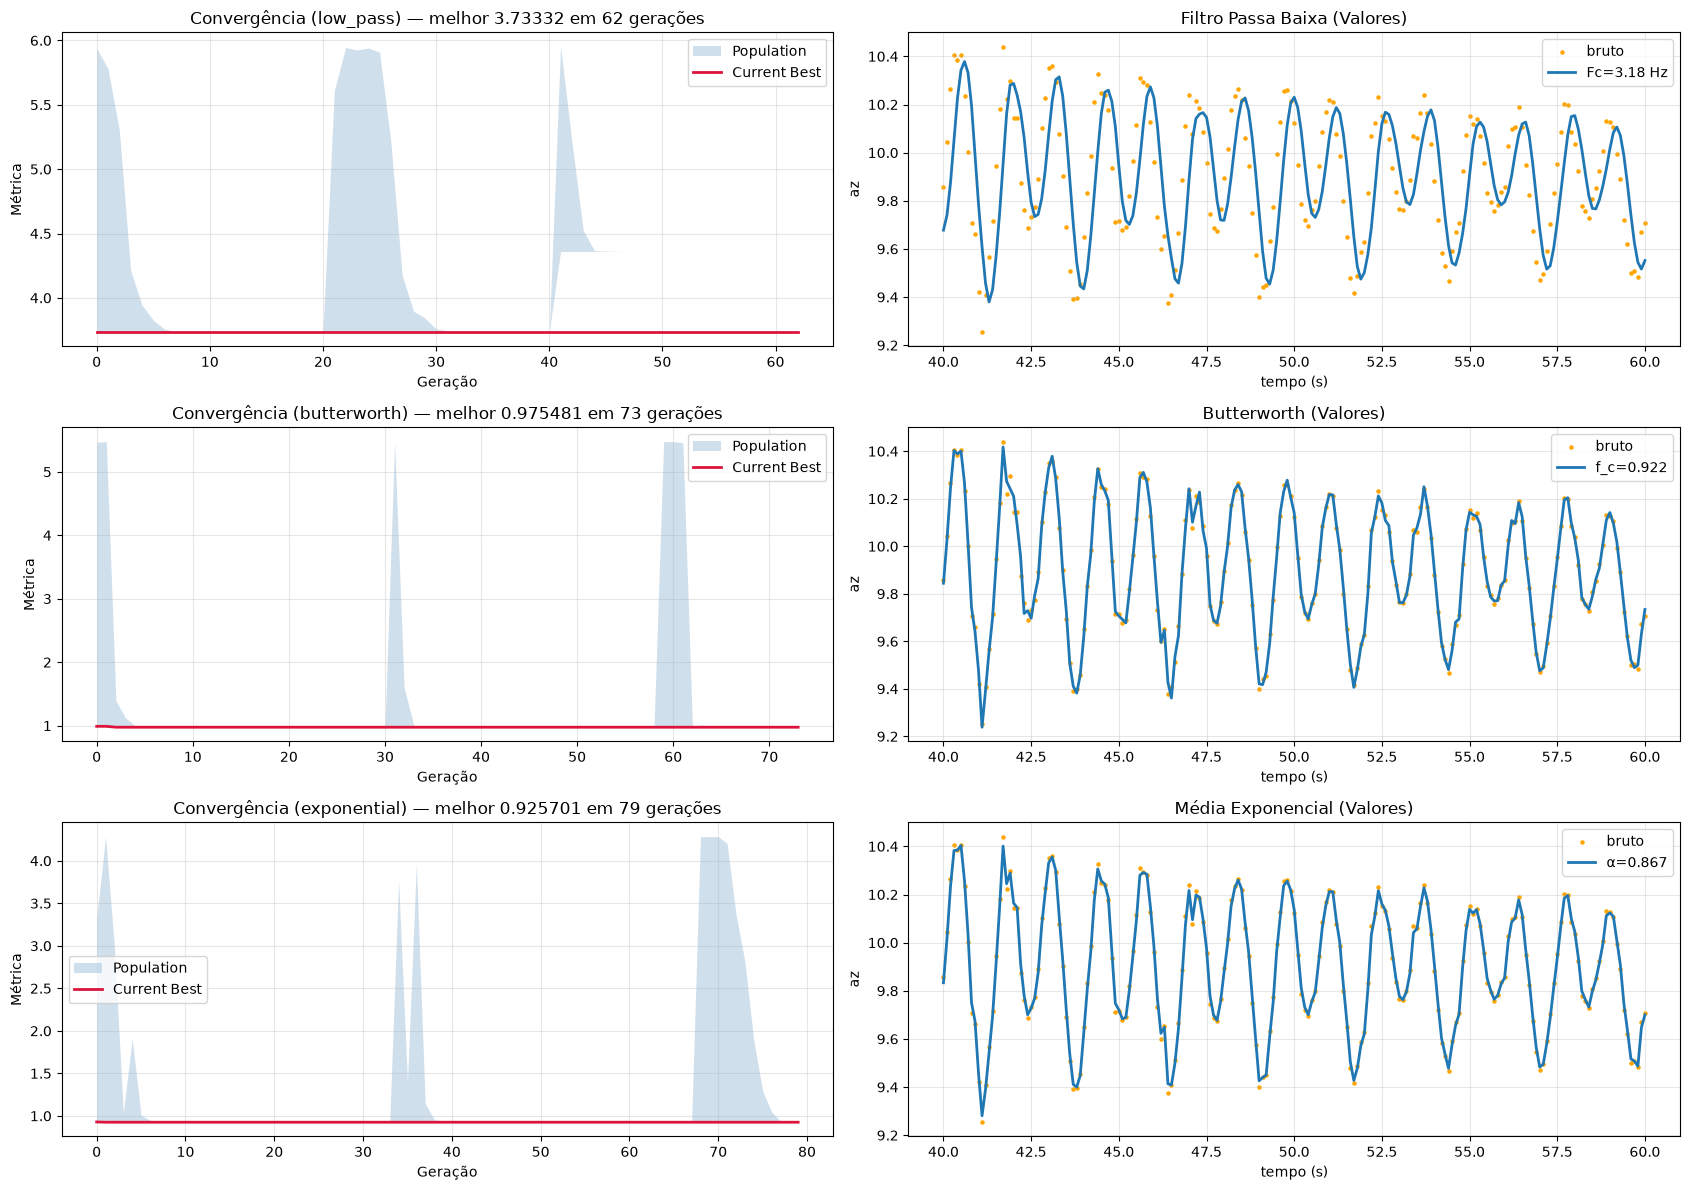

,error,params
exponential,0.925701,{'log_fc': 0.5060270363983556}
butterworth,0.975481,{'log_fc': 0.6638858603963824}
low_pass,3.733321,{'log_fc': 0.5028501273058662}


In [15]:
TARGET = 'az'
models = {
    filter: NatureSelector('genetic', {
            'objective': lambda params, filter=filter: objective(filter, params),
            'maximize': False, 'verbose': True, 'variables': option['variables'], **SEARCH  
        }, n_gaussian=RUNS
    ) for filter, option in FILTERS.items()
}

for model in models.values():
    model.update()

plt.figure(figsize=(17, 4*len(models)))
for i, (filter, model) in enumerate(models.items()):
    portrait      = model.portrait()
    portrait.name = filter
    plt.subplot(len(models), 2, 2*i + 1); portrait.metrics(plt.gca())
    plt.subplot(len(models), 2, 2*i + 2); FILTERS[filter]['filter'](**model.best).test(df[MOTION], TARGET, LIMITS)

plt.tight_layout()
plt.show()

rankings[TARGET] = {filter: {'error': model.score, 'params': model.best} for filter, model in models.items()}
pd.DataFrame(rankings[TARGET]).T.sort_values('error')

### VELOCIDADE ANGULAR EM X ($\omega_x$)

genetic: 100%|██████████| 22110/22110 [00:12<00:00, 1760.04ev/s, best=0.998388, pop=120]


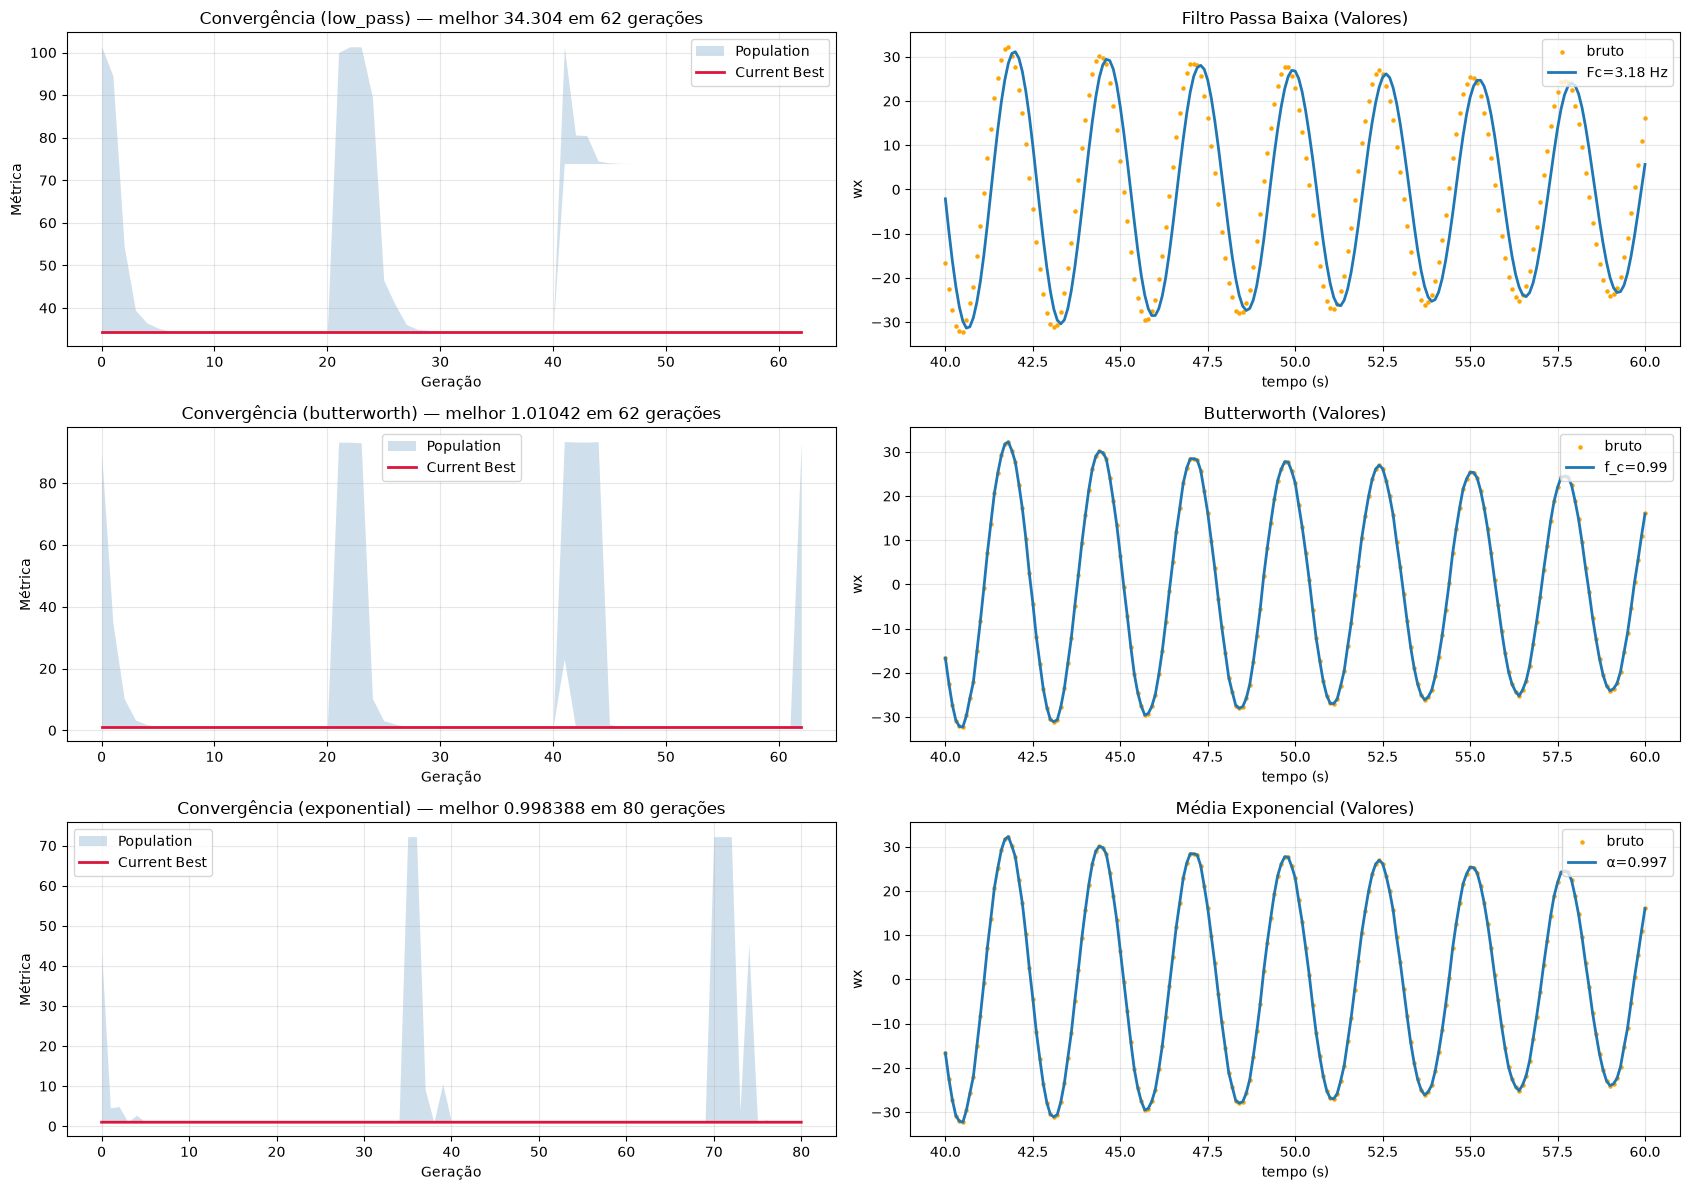

,error,params
exponential,0.998388,{'log_fc': 0.9607997095863923}
butterworth,1.010421,{'log_fc': 0.6946051989335688}
low_pass,34.304019,{'log_fc': 0.5028501273058662}


In [16]:
TARGET = 'wx'
models = {
    filter: NatureSelector('genetic', {
            'objective': lambda params, filter=filter: objective(filter, params),
            'maximize': False, 'verbose': True, 'variables': option['variables'], **SEARCH
        }, n_gaussian=RUNS
    ) for filter, option in FILTERS.items()
}

for model in models.values():
    model.update()

plt.figure(figsize=(17, 4*len(models)))
for i, (filter, model) in enumerate(models.items()):
    portrait      = model.portrait()
    portrait.name = filter 
    plt.subplot(len(models), 2, 2*i + 1); portrait.metrics(plt.gca())
    plt.subplot(len(models), 2, 2*i + 2); FILTERS[filter]['filter'](**model.best).test(df[MOTION], TARGET, LIMITS)

plt.tight_layout()
plt.show()

rankings[TARGET] = {filter: {'error': model.score, 'params': model.best} for filter, model in models.items()}
pd.DataFrame(rankings[TARGET]).T.sort_values('error')

### VELOCIDADE ANGULAR EM Y ($\omega_y$)

genetic: 100%|██████████| 22110/22110 [00:12<00:00, 1736.93ev/s, best=0.958413, pop=120]


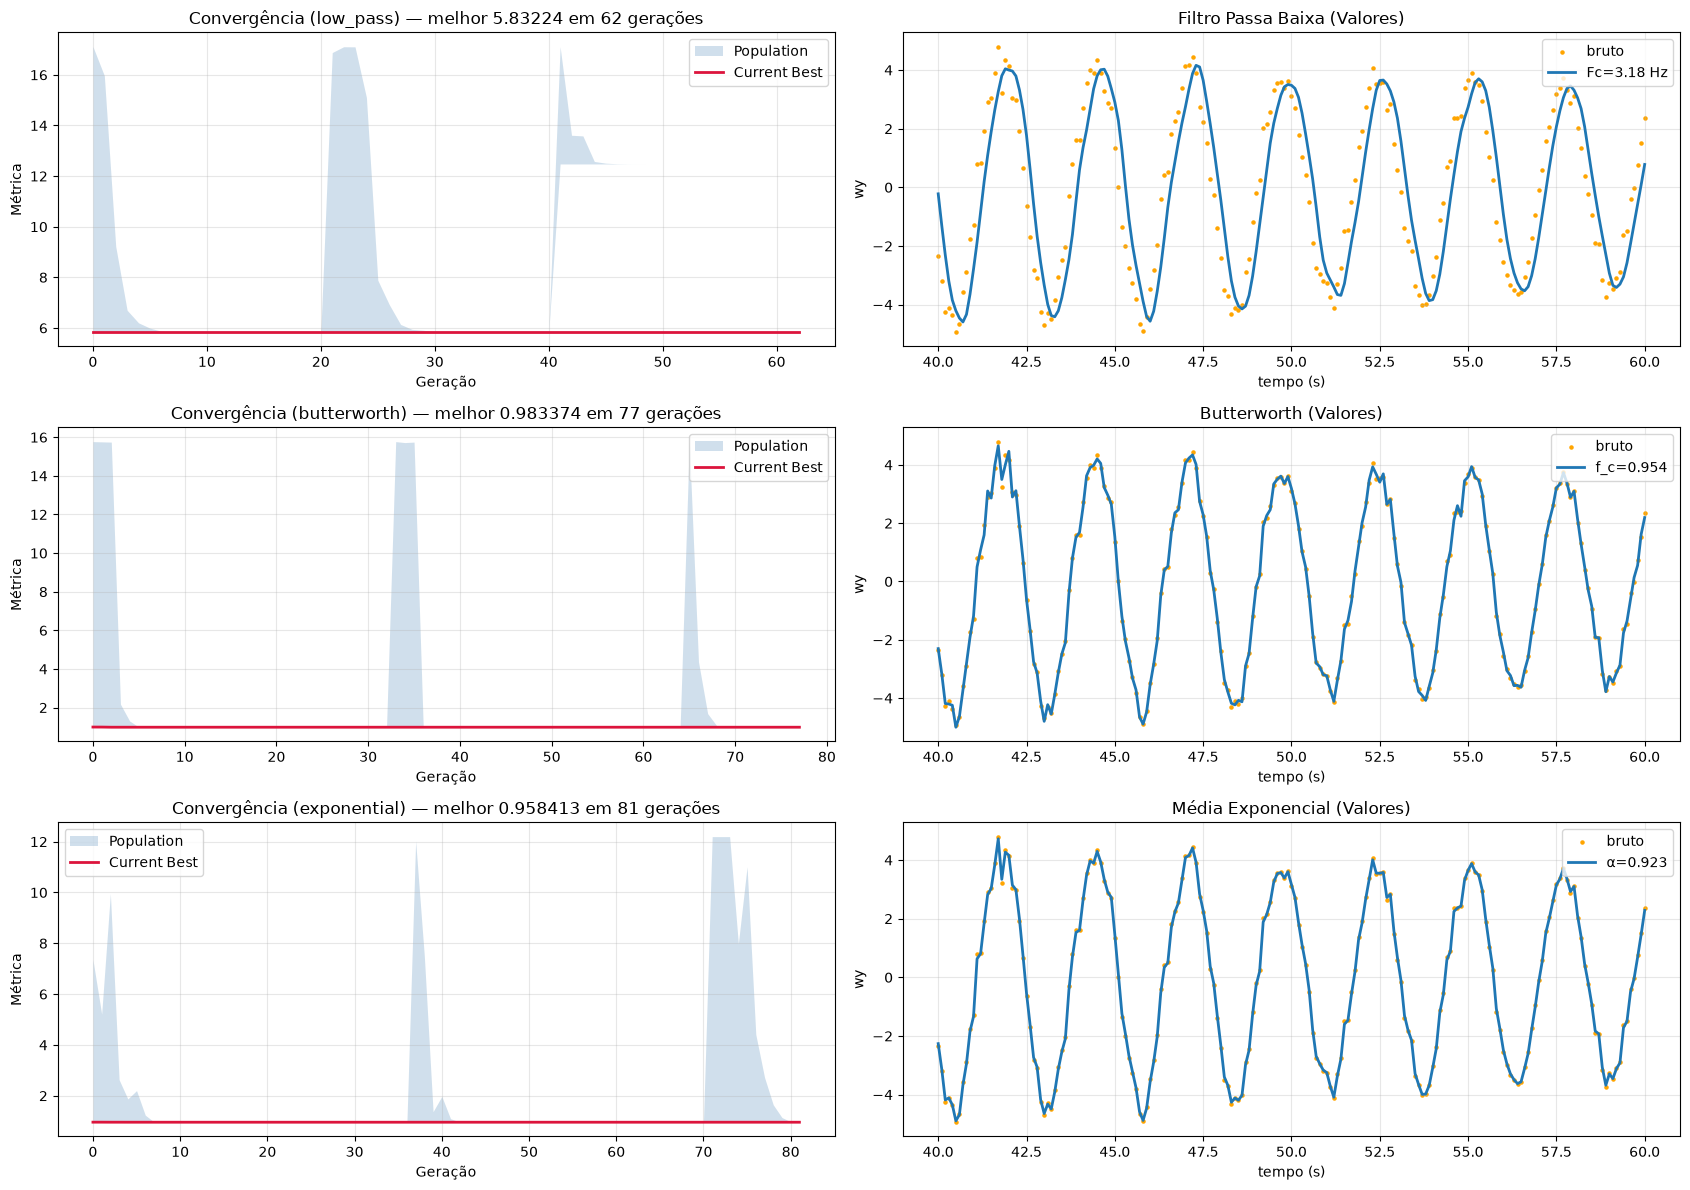

,error,params
exponential,0.958413,{'log_fc': 0.6107434613395559}
butterworth,0.983374,{'log_fc': 0.6785543679951145}
low_pass,5.832239,{'log_fc': 0.5028501273058662}


In [17]:
TARGET = 'wy'
models = {
    filter: NatureSelector('genetic', {
            'objective': lambda params, filter=filter: objective(filter, params),
            'maximize': False, 'verbose': True, 'variables': option['variables'], **SEARCH
        }, n_gaussian=RUNS
    ) for filter, option in FILTERS.items()
}

for model in models.values():
    model.update()

plt.figure(figsize=(17, 4*len(models)))
for i, (filter, model) in enumerate(models.items()):
    portrait      = model.portrait()
    portrait.name = filter 
    plt.subplot(len(models), 2, 2*i + 1); portrait.metrics(plt.gca())
    plt.subplot(len(models), 2, 2*i + 2); FILTERS[filter]['filter'](**model.best).test(df[MOTION], TARGET, LIMITS)

plt.tight_layout()
plt.show()

rankings[TARGET] = {filter: {'error': model.score, 'params': model.best} for filter, model in models.items()}
pd.DataFrame(rankings[TARGET]).T.sort_values('error')

### VELOCIDADE ANGULAR EM Z ($\omega_z$)

genetic: 100%|██████████| 22110/22110 [00:12<00:00, 1752.47ev/s, best=0.679786, pop=120]


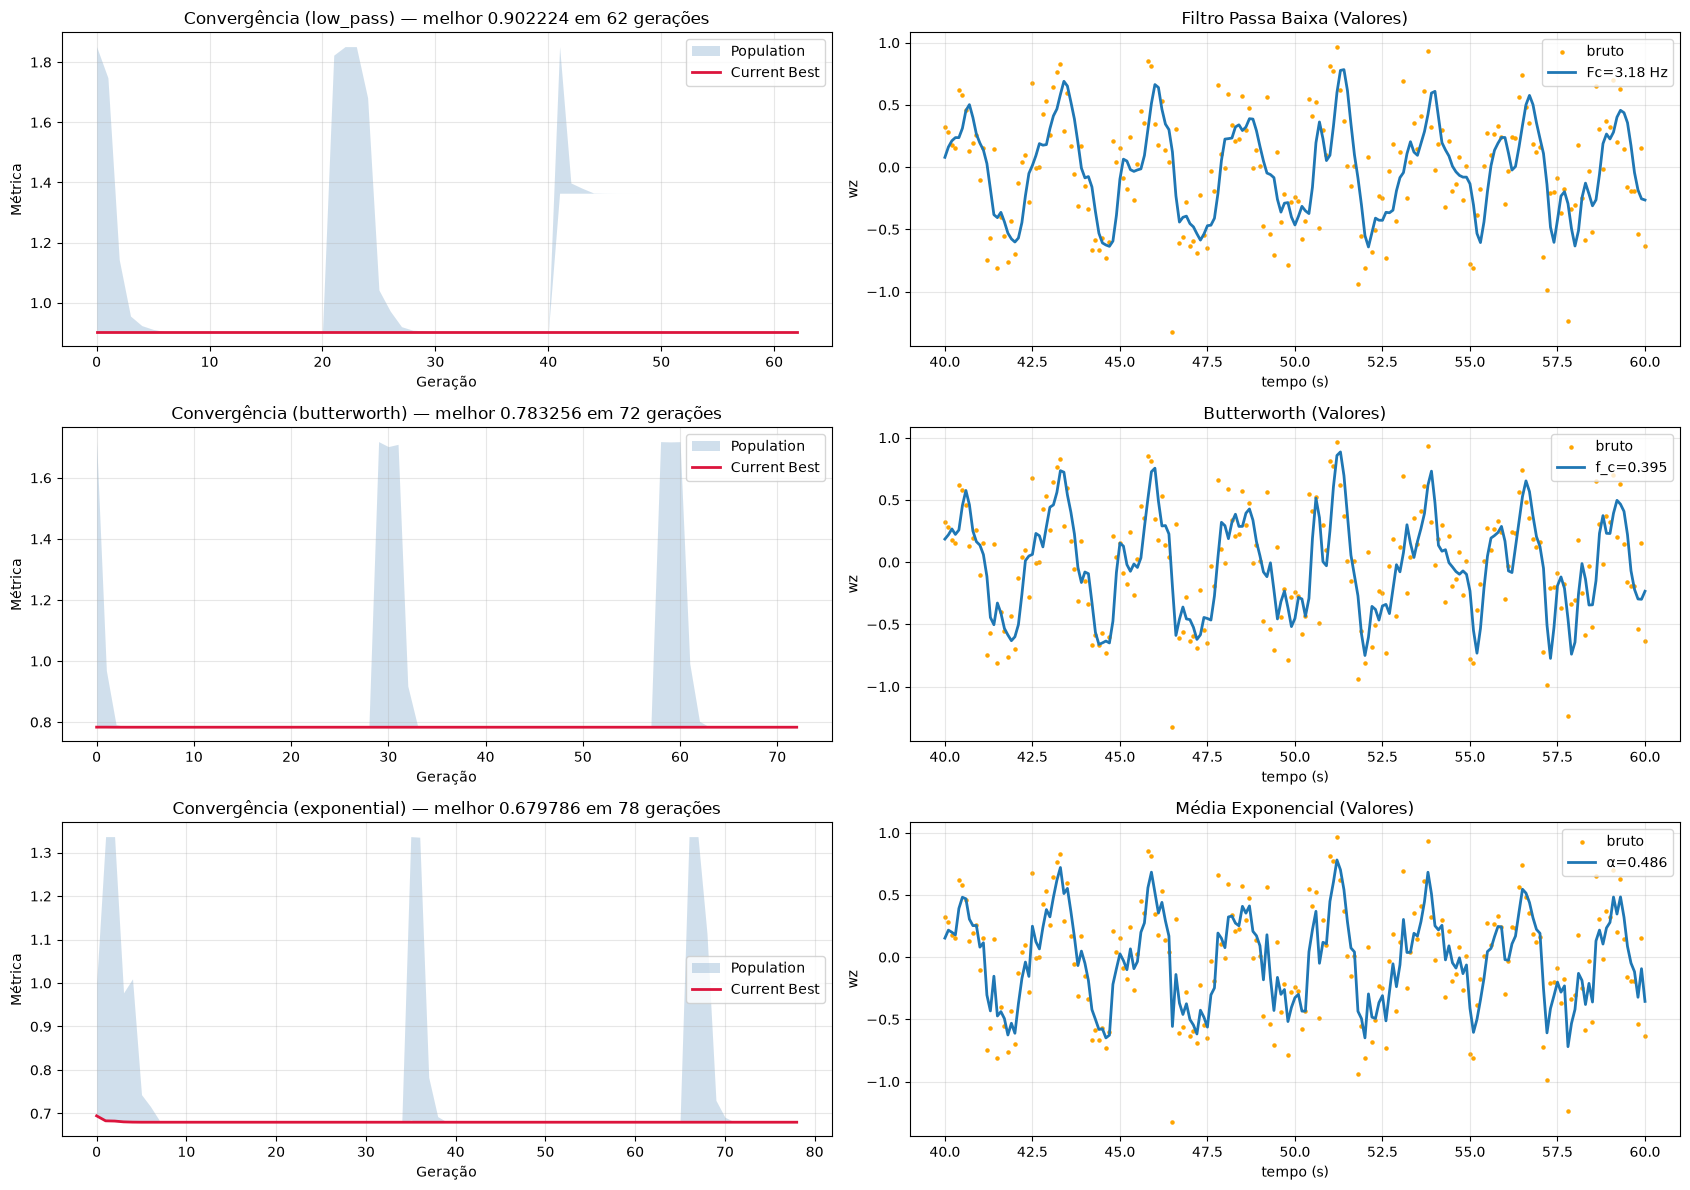

,error,params
exponential,0.679786,{'log_fc': 0.024401778348316902}
butterworth,0.783256,{'log_fc': 0.295743002906484}
low_pass,0.902224,{'log_fc': 0.5028501273058662}


In [18]:
TARGET = 'wz'
models = {
    filter: NatureSelector('genetic', {
            'objective': lambda params, filter=filter: objective(filter, params),
            'maximize': False, 'verbose': True, 'variables': option['variables'], **SEARCH
        }, n_gaussian=RUNS
    ) for filter, option in FILTERS.items()
}

for model in models.values():
    model.update()

plt.figure(figsize=(17, 4*len(models)))
for i, (filter, model) in enumerate(models.items()):
    portrait      = model.portrait()
    portrait.name = filter  
    plt.subplot(len(models), 2, 2*i + 1); portrait.metrics(plt.gca())
    plt.subplot(len(models), 2, 2*i + 2); FILTERS[filter]['filter'](**model.best).test(df[MOTION], TARGET, LIMITS)

plt.tight_layout()
plt.show()

rankings[TARGET] = {filter: {'error': model.score, 'params': model.best} for filter, model in models.items()}
pd.DataFrame(rankings[TARGET]).T.sort_values('error')

# ESCOLHA DO MELHOR FILTRO
- A escolha é pela métrica: $\varepsilon$ é objetivo, relativo ao sinal cru, e escolher no olho entre 3 filtros × 6 variáveis não seria reprodutível; os gráficos de cada variável ficam como conferência
- Com $\varepsilon$ perto de 1 filtrar em tempo real não compensa: a média exponencial chega a $\alpha = 1$, que é passar o sinal adiante

In [19]:
CHOSEN = {var: min(ranking, key=lambda filter: ranking[filter]['error']) for var, ranking in rankings.items()}

chosen = {}
for var, filter in CHOSEN.items():
    chosen[var] = {
        'name': filter,
        'error': rankings[var][filter]['error'],
        'params': rankings[var][filter]['params']
    }

chosen = pd.DataFrame(chosen).T
chosen

,name,error,params
ax,exponential,0.538901,{'log_fc': -0.5017554408937143}
ay,exponential,0.714667,{'log_fc': 0.0956083868728886}
az,exponential,0.925701,{'log_fc': 0.5060270363983556}
wx,exponential,0.998388,{'log_fc': 0.9607997095863923}
wy,exponential,0.958413,{'log_fc': 0.6107434613395559}
wz,exponential,0.679786,{'log_fc': 0.024401778348316902}


# SALVANDO OS FILTROS
- `filtered.csv` leva o dataset inteiro com cada sensor filtrado e o cru em `_raw`: é a entrada do `2 - Correction`

In [20]:
df = df.rename(columns={col: f'{col}_raw' for col in SENSORS})

for var, row in chosen.iterrows():
    df[var] = FILTERS[row['name']]['filter'](**row['params']).apply(df[f'{var}_raw'])

df.to_csv(f'{RESULTS}/filtered.csv', index=None)
df

,time,static,tmp,ax_raw,ay_raw,az_raw,wx_raw,wy_raw,wz_raw,pitch,...,ref_yaw,ref_wx,ref_wy,ref_wz,ax,ay,az,wx,wy,wz
0,0.0,False,53.0,0.194623,-0.614769,10.733555,-47.92960,-6.92455,1.16726,18.043,...,2.771970,-48.363254,-0.461426,0.424375,0.194623,-0.614769,10.733555,-47.929600,-6.924550,1.167260
1,0.1,False,52.9,0.294719,-0.532550,11.618576,-58.13591,-8.13221,1.05996,12.732,...,2.723841,-56.744132,1.081554,0.104249,0.212594,-0.570125,11.500547,-58.103128,-8.039228,1.115162
2,0.2,False,53.1,0.256924,-2.312996,12.899422,-67.53252,-8.42212,1.95110,6.586,...,2.667691,-63.259749,-0.383746,0.248578,0.220553,-1.516485,12.712865,-67.502234,-8.392640,1.521041
3,0.3,False,53.3,0.425020,-0.455019,12.406766,-67.39252,-9.92099,1.05936,-0.016,...,2.743322,-66.654402,0.041597,0.372268,0.257263,-0.940121,12.447588,-67.392872,-9.803317,1.296878
4,0.4,False,52.9,0.271203,-0.208931,12.362390,-66.62502,-9.44709,1.97845,-6.779,...,2.624720,-67.172037,1.487548,0.737216,0.259766,-0.543093,12.373753,-66.627486,-9.474517,1.627807
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1795,279.4,True,55.5,0.269369,-0.416959,9.760873,-0.09321,-0.21920,-0.25104,-2.510,...,6.371291,0.026304,0.007389,0.002918,0.232602,-0.426468,9.754616,-0.093293,-0.185545,-0.139490
1796,279.5,True,55.6,0.235938,-0.402014,9.717615,-0.09929,-0.00493,0.03678,-2.509,...,6.371291,-0.006860,0.005699,-0.000058,0.233201,-0.413190,9.722550,-0.099271,-0.018836,-0.053904
1797,279.6,True,55.4,0.257170,-0.404622,9.768983,-0.18597,0.50338,-0.40111,-2.506,...,6.371291,0.001138,-0.030184,-0.002684,0.237504,-0.408538,9.762790,-0.185692,0.463173,-0.222486
1798,279.7,True,55.6,0.266545,-0.485586,9.796167,0.06592,0.14588,0.14609,-2.506,...,6.377020,-0.002625,-0.056662,0.004405,0.242718,-0.450374,9.791716,0.065112,0.170310,-0.043528


In [21]:
os.makedirs('Backup', exist_ok=True)
saved  = [name for name in os.listdir('Backup') if name.startswith('filters_')]
index  = len(saved) + 1

output = f'Backup/filters_{index}'
os.makedirs(output, exist_ok=True)

results = {
    'filters':  chosen.to_dict('index'),
    'ranking':  rankings,
    'search':   {**SEARCH, 'runs': RUNS, 'variables': {name: option['variables'] for name, option in FILTERS.items()}},
    'dataset':  {'path': SOURCE, 'samples': int(MOTION.sum()), 'dt': float(dt)}
}

record = {
    'strategy': 'filters',
    'backup':   f'1 - Filters/{output}',
    'filters':  {var: {'name': row['name'], 'error': row['error']} for var, row in chosen.iterrows()}
}

pd.Series(results).to_json(f'{output}/info.json', indent=4)
pd.Series(record).to_json(f'{RESULTS}/filters.json', indent=4)
print(output, '->', f'{RESULTS}/filters.json')
record

Backup/filters_1 -> ../Dataset/test1/results/filters.json


{'strategy': 'filters',
 'backup': '1 - Filters/Backup/filters_1',
 'filters': {'ax': {'name': 'exponential', 'error': 0.5389014887797285},
  'ay': {'name': 'exponential', 'error': 0.7146672767124961},
  'az': {'name': 'exponential', 'error': 0.9257007365661586},
  'wx': {'name': 'exponential', 'error': 0.9983878003737116},
  'wy': {'name': 'exponential', 'error': 0.9584126968877339},
  'wz': {'name': 'exponential', 'error': 0.6797863599960629}}}

# EXPORTANDO PARA O FIRMWARE
- O MRU roda em cada eixo o filtro escolhido aqui, na taxa do Kernel, antes de o streamer decimar para a frequência de saída: é o anti-aliasing da etapa 1
- Vai o corte em Hz, que é o que a busca já ajustou: o firmware refaz os coeficientes no $\Delta t$ do Kernel, que pode não ser o do ensaio
- Na média exponencial o corte é $f_c = 1/(2\pi\tau)$, com $\alpha = 1 - e^{-2\pi f_c \Delta t}$ dos dois lados

In [22]:
FIRMWARE = '../../Hardware/Embedded/Main/objects/processing/filters'
TYPES    = {'butterworth': 'FILTER_BUTTERWORTH', 'low_pass': 'FILTER_LOW_PASS', 'exponential': 'FILTER_EXPONENTIAL'}

cutoff = {var: 10**row['params']['log_fc'] for var, row in chosen.iterrows()}
types  = ', '.join(TYPES[chosen.loc[var, 'name']] for var in SENSORS)
values = ', '.join(f'{cutoff[var]:.6f}f' for var in SENSORS)

header = f'''#ifndef FILTERS_CONFIG_H
#define FILTERS_CONFIG_H

// GERADO POR Calibration/1 - Filters/1 - Model.ipynb EM {datetime.date.today():%d/%m/%Y}
static const int FILTERS_TYPE[6] = {{{types}}};    // {', '.join(SENSORS)}
static const float FILTERS_FC[6] = {{{values}}};    // Hz: -3 dB no butterworth, polo no low_pass, 1/(2 pi tau) na exponencial

#endif
'''

open(f'{FIRMWARE}/config.h', 'w').write(header)
display(pd.DataFrame({'filtro': chosen.name, 'corte (Hz)': cutoff, 'erro': chosen.error}))
print(header)

,filtro,corte (Hz),erro
ax,exponential,0.314952,0.538901
ay,exponential,1.246259,0.714667
az,exponential,3.206469,0.925701
wx,exponential,9.136918,0.998388
wy,exponential,4.080783,0.958413
wz,exponential,1.057796,0.679786


#ifndef FILTERS_CONFIG_H
#define FILTERS_CONFIG_H

// GERADO POR Calibration/1 - Filters/1 - Model.ipynb EM 20/10/2026
static const int FILTERS_TYPE[6] = {FILTER_EXPONENTIAL, FILTER_EXPONENTIAL, FILTER_EXPONENTIAL, FILTER_EXPONENTIAL, FILTER_EXPONENTIAL, FILTER_EXPONENTIAL};    // ax, ay, az, wx, wy, wz
static const float FILTERS_FC[6] = {0.314952f, 1.246259f, 3.206469f, 9.136918f, 4.080783f, 1.057796f};    // Hz: -3 dB no butterworth, polo no low_pass, 1/(2 pi tau) na exponencial

#endif

